# 환경 설정

## 한글화 코드

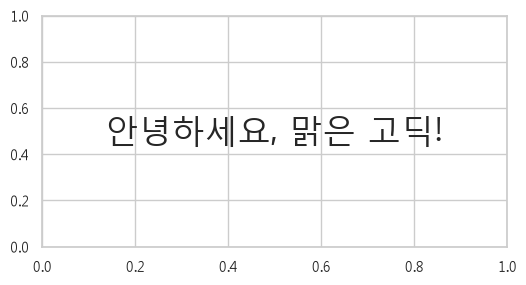

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns

# seaborn 스타일을 먼저 적용
sns.set_theme(style="whitegrid")

# Windows 한글 글꼴 설정
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

# 한글 표시 확인
plt.figure(figsize=(6, 3))
plt.text(
    0.5, 0.5,
    "안녕하세요, 맑은 고딕!",
    ha="center",
    va="center",
    size=24
)
plt.show()

## MySQL 연결

In [2]:
import pandas as pd
from getpass import getpass
from sqlalchemy import create_engine, URL, text

url = URL.create(
    drivername="mysql+pymysql",
    username="root",
    password=getpass("MySQL 비밀번호: "),
    host="localhost",
    port=3306,
    database="final",
    query={"charset": "utf8mb4"},
)

engine = create_engine(url, pool_pre_ping=True)

# 연결 확인
with engine.connect() as conn:
    print(conn.execute(text("SELECT VERSION()")).scalar())

8.0.37


In [3]:
query = "SELECT * FROM accounts_user LIMIT 5"

with engine.connect() as conn:
    df = pd.read_sql_query(text(query), conn)

df.head()

,id,is_superuser,is_staff,gender,point,friend_id_list,is_push_on,created_at,block_user_id_list,hide_user_id_list,ban_status,report_count,alarm_count,pending_chat,pending_votes,group_id
0,831956,1,1,None,600,"[1292473, 913158, 1488461, 1064695, 1043565, 1...",0,2023-03-29 03:44:14.047130,[],[],N,0,0,0,0,NaN
1,831962,0,0,F,2248,"[833025, 832642, 982531, 879496, 838541, 83752...",1,2023-03-29 05:18:56.162368,[],[],N,253,40878,5499,110,12.0
2,832151,0,0,M,1519,"[838785, 982531, 882567, 879496, 838541, 83649...",0,2023-03-29 12:56:34.989468,[],[],N,0,37,0,47,1.0
3,832340,0,0,F,57,"[841345, 982531, 838785, 963714, 882567, 83252...",1,2023-03-29 12:56:35.020790,[],[],N,0,19,0,21,1.0
4,832520,0,0,M,1039,"[874050, 849763, 874212, 844297, 838541, 84004...",0,2023-03-29 12:56:35.049311,[],[],N,0,29,0,15,12.0


## DataFrame에 저장

In [14]:
import pandas as pd
from sqlalchemy import text

params = {
    "start_at": "2023-05-04 00:00:00",
    "end_at": "2024-05-06 00:00:00",
}

queries = {
    "polls_question": """
        SELECT
            id,
            TRIM(question_text) AS question_text,
            created_at
        FROM final.polls_question
    """,

    "polls_questionreport": """
        SELECT
            id,
            TRIM(reason) AS reason,
            created_at,
            question_id,
            user_id
        FROM final.polls_questionreport
        WHERE created_at >= :start_at
          AND created_at < :end_at
    """,

    "polls_usercandidate": """
        SELECT
            id,
            created_at,
            question_piece_id,
            user_id
        FROM final.polls_usercandidate
        WHERE created_at >= :start_at
          AND created_at < :end_at
    """,

    "polls_questionset": """
        SELECT
            id,
            question_piece_id_list,
            opening_time,
            status,
            user_id
        FROM final.polls_questionset
        WHERE opening_time >= created_at
          AND status = 'F'
          AND created_at >= :start_at
          AND created_at < :end_at
    """,

    "polls_questionpiece": """
        SELECT
            id,
            is_voted,
            question_id,
            is_skipped
        FROM final.polls_questionpiece
        WHERE created_at >= :start_at
          AND created_at < :end_at
    """,

    "accounts_userquestionrecord": """
        SELECT
            id,
            status,
            created_at,
            chosen_user_id,
            question_id,
            user_id,
            question_piece_id,
            has_read,
            answer_status,
            answer_updated_at,
            report_count,
            opened_times
        FROM final.accounts_userquestionrecord
        WHERE answer_status <> 'P'
          AND created_at >= :start_at
          AND created_at < :end_at
    """,

    # 가입일 제한 없이 일반 유저 전체 조회
    "accounts_user": """
        SELECT
            id,
            is_superuser,
            is_staff,
            gender,
            friend_id_list,
            is_push_on,
            created_at,
            block_user_id_list,
            hide_user_id_list,
            ban_status,
            report_count,
            group_id
        FROM final.accounts_user
        WHERE is_superuser = 0
          AND is_staff = 0
    """,

    "accounts_timelinereport": """
        SELECT
            id,
            TRIM(reason) AS reason,
            created_at,
            reported_user_id,
            user_id,
            user_question_record_id
        FROM final.accounts_timelinereport
        WHERE created_at >= :start_at
          AND created_at < :end_at
    """,

    "accounts_school": """
        SELECT
            id,
            student_count,
            school_type
        FROM final.accounts_school
    """,

    "accounts_group": """
        SELECT
            id,
            school_id
        FROM final.accounts_group
    """,

    "accounts_blockrecord": """
        SELECT
            id,
            TRIM(reason) AS reason,
            created_at,
            block_user_id,
            user_id
        FROM final.accounts_blockrecord
        WHERE created_at >= :start_at
          AND created_at < :end_at
    """,

    # 생성일 컬럼이 없어 전체 조회
    "accounts_attendance": """
        SELECT
            id,
            attendance_date_list,
            user_id
        FROM final.accounts_attendance
    """,
}

dfs = {}

with engine.connect() as conn:
    for table_name, query in queries.items():
        dfs[table_name] = pd.read_sql_query(
            text(query),
            conn,
            params=params,
        )

        df = dfs[table_name]
        print(f"{table_name}: {len(df):,}행 × {len(df.columns)}열")

# 개별 DataFrame 변수
df_question = dfs["polls_question"]
df_questionreport = dfs["polls_questionreport"]
df_usercandidate = dfs["polls_usercandidate"]
df_questionset = dfs["polls_questionset"]
df_questionpiece = dfs["polls_questionpiece"]
df_userquestionrecord = dfs["accounts_userquestionrecord"]
df_user = dfs["accounts_user"]
df_timelinereport = dfs["accounts_timelinereport"]
df_school = dfs["accounts_school"]
df_group = dfs["accounts_group"]
df_blockrecord = dfs["accounts_blockrecord"]
df_attendance = dfs["accounts_attendance"]

polls_question: 5,025행 × 3열
polls_questionreport: 48,928행 × 5열
polls_usercandidate: 4,452,529행 × 4열
polls_questionset: 141,909행 × 5열
polls_questionpiece: 1,177,414행 × 4열
accounts_userquestionrecord: 1,128,249행 × 12열
accounts_user: 677,081행 × 12열
accounts_timelinereport: 208행 × 6열
accounts_school: 5,951행 × 3열
accounts_group: 84,515행 × 2열
accounts_blockrecord: 19,481행 × 5열
accounts_attendance: 349,637행 × 3열


In [15]:
query_attendance = """
SELECT
    id,
    attendance_date_list,
    user_id
FROM final.accounts_attendance
"""

with engine.connect() as conn:
    df_attendance = pd.read_sql_query(text(query_attendance), conn)

dfs["accounts_attendance"] = df_attendance

print(f"accounts_attendance: {len(df_attendance):,}행 × {len(df_attendance.columns)}열")

df_attendance.head()

accounts_attendance: 349,637행 × 3열


,id,attendance_date_list,user_id
0,1,"[""2023-05-27"", ""2023-05-28"", ""2023-05-29"", ""20...",1446852
1,2,"[""2023-05-27"", ""2023-05-29"", ""2023-05-30"", ""20...",1359398
2,3,"[""2023-05-27"", ""2023-05-29"", ""2023-05-30"", ""20...",1501542
3,4,"[""2023-05-27"", ""2023-05-28"", ""2023-05-29"", ""20...",1507767
4,5,"[""2023-05-27"", ""2023-05-28"", ""2023-05-29"", ""20...",1287453


# 전처리

## 중복값 확인

In [16]:
duplicate_results = []

for table_name, df in dfs.items():
    duplicate_results.append({
        "테이블": table_name,
        "전체 행 수": len(df),

        # 첫 행을 제외한 추가 중복 행 수
        "전체 컬럼 중복 행 수": int(df.duplicated().sum()),

        # 기본키 중복 및 누락
        "ID 중복 수": (
            int(df["id"].duplicated().sum())
            if "id" in df.columns else pd.NA
        ),
        "ID 결측 수": (
            int(df["id"].isna().sum())
            if "id" in df.columns else pd.NA
        ),
    })

df_duplicate_summary = pd.DataFrame(duplicate_results)

df_duplicate_summary

,테이블,전체 행 수,전체 컬럼 중복 행 수,ID 중복 수,ID 결측 수
0,polls_question,5025,0,0,0
1,polls_questionreport,48928,0,0,0
2,polls_usercandidate,4452529,0,0,0
3,polls_questionset,141909,0,0,0
4,polls_questionpiece,1177414,0,0,0
5,accounts_userquestionrecord,1128249,0,0,0
6,accounts_user,677081,0,0,0
7,accounts_timelinereport,208,0,0,0
8,accounts_school,5951,0,0,0
9,accounts_group,84515,0,0,0


# EDA

## 전체 질문 신고 순위 확인

### 질문 신고 순위

### 질문 신고 사유 순위

## 학생들의 신고·차단 행동 패턴

### 성별에 대한 패턴 분석

### 학급에 대한 패턴 분석

### 질문 신고가 유저 신고, 차단, 숨김에 영향이 있는지?

## 후속조치 확인

### 신고 당한 이후에도 비슷한 비중으로 질문이 등장했는가?

### 위에서 확인했던 질문에 대한 라벨링 추가